# Analysis of September temperatures in Bangalore

This code is based on the code obtained from the ECMWF code for France. In Bangalore, we have been experiencing elevated temperatures and especially so in the month of September.

The idea here is to show using the original data formats (netcdf/.nc) how long it can take to download the data.

This code also shows how to work with the xarray package. This package is not only useful for old data formats but also for the newer formats (zarr, cog, etc) and shows some basic commands to answer our question whether it has been hotter in Bangalore during the month of September in 2026.

This code is based on this ECMWF tutorial: [Analysis of September 2020 European Heatwave using ERA5 Climate Reanalysis Data from C3S](https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-heatwave.html)

## Creating an account with the CDS

Whether you work with the older formats or with the newer formats, you will need to create an account with the [Climate Data Store](https://cds.climate.copernicus.eu/).

You will also need an API key. You can find this in your account information if you click on "Your profile".

![logo](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_01.PNG?raw=1)

Then, you need to grab the API key:



There are several ways that you can proceed with using the API key. The easiest and fastest is to directly paste it in the code below (please see below).

![api](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_02.png?raw=1)


## Finding the right data

We want to look at daily data for the month of september for temperature for Bangalore.

The CDS has many data. For this example, we need daily data and this across the month of September across several years across the latitude and longitudes of Bangalore.

The minimum and maximum longitude and latitude for Bangalore are approximately:

- longitude minimum and maximum: 77.440784, 77.7722854
- latitude minimum and maximum: 12.8335167, 13.1572602

For simplicity, we will round the numbers.

This was obtained the using a [geojson file for Bangalore](https://data.opencity.in/dataset/gba-wards-delimitation-2025/resource/9013d656-8051-4e2d-9648-46efd0d86d3d) and then using this [geojson.io](https://geojson.io/) and look at the corner points. I am sure there are other ways!

In order to find the right dataset, we can go to the [CDS website](https://cds.climate.copernicus.eu/datasets) where we find an overview of the datasets. We would like to have daily data. More specifically, we select [ERA5 hourly data on single levels from 1940 to present](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview) similar to the example in the original tutorial for Lille, France.

## Installing packages

In order to do this type of analysis using the older way/formats (grib, netcdf (.nc) and obtain the data from the ECWMF,

#### Install CDS API

To install the CDS API, run the following command. We use an exclamation mark to pass the command to the shell:

In [ ]:
!pip install cdsapi cartopy --quiet

#### Import libraries

We will be working with data in NetCDF format. To best handle this data we will use libraries for working with multidimensional arrays, in particular Xarray. We will also need libraries for plotting and viewing data, in this case we will use Matplotlib and Cartopy.

In [ ]:
# CDS API
import cdsapi
import os

# Libraries for working with multidimensional arrays
import numpy as np
import xarray as xr

# Libraries for plotting and visualising data
## import matplotlib.path as mpath
import matplotlib.pyplot as plt
## import cartopy.crs as ccrs
## from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
## import cartopy.feature as cfeature

# Disable warnings for data download via API
import urllib3
urllib3.disable_warnings()

#### Enter your CDS API key

We will request data from the Climate Data Store (CDS) programmatically with the help of the CDS API. Let us make use of the option to manually set the CDS API credentials. First, you have to define two variables: `URL` and `KEY` which build together your CDS API key. The string of characters that make up your KEY include your personal User ID and CDS API key. To obtain these, first register or login to the CDS (https://cds.climate.copernicus.eu), then visit https://cds.climate.copernicus.eu/how-to-api and copy the string of characters listed after "key:". Replace the `#########` below with this string.

In [ ]:
URL = 'https://cds.climate.copernicus.eu/api'
KEY = 'FILL IN YOUR CDS API KEY HERE'

Here we specify a data directory in which we will download our data and all output files that we will generate:

In [ ]:
DATADIR = './'

Navigate to the [ERA5 hourly data on single levels from 1940 to present](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview) of the CDS website, click on the "Download" and fill in the following values:

![img34](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_3_4.PNG?raw=1)

![img56](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_5_6.PNG?raw=1)

![img7](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_07.PNG?raw=1)

After clicking on "Show API request, the following code shows. Follow the example from the tutorial to generate the code that can pull the data:

![img8](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_08.PNG?raw=1)

Using the code of the tutorial:

In [ ]:
c = cdsapi.Client(url=URL, key=KEY)
c.retrieve(
    'reanalysis-era5-single-levels',
    {
        'product_type': 'reanalysis',
        'data_format': 'netcdf_legacy',
        'variable': '2m_temperature',
        'year': [

            '1979', '1980', '1981',
            '1982', '1983', '1984',
            '1985', '1986', '1987',
            '1988', '1989', '1990',
            '1991', '1992', '1993',
            '1994', '1995', '1996',
            '1997', '1998', '1999',
            '2000', '2001', '2002',
            '2003', '2004', '2005',
            '2006', '2007', '2008',
            '2009', '2010', '2011',
            '2012', '2013', '2014',
            '2015', '2016', '2017',
            '2018', '2019', '2020',
            '2021', '2022', '2023',
             '2024', '2025', '2026'
        ],
        'month': '09',
        'day': [
            '01', '02', '03',
            '04', '05', '06',
            '07', '08', '09',
            '10', '11', '12',
            '13', '14', '15',
            '16', '17', '18',
            '19', '20', '21',
            '22', '23', '24',
            '25', '26', '27',
            '28', '29', '30',
        ],
        'time': [
            '00:00', '01:00', '02:00',
            '03:00', '04:00', '05:00',
            '06:00', '07:00', '08:00',
            '09:00', '10:00', '11:00',
            '12:00', '13:00', '14:00',
            '15:00', '16:00', '17:00',
            '18:00', '19:00', '20:00',
            '21:00', '22:00', '23:00',
        ],
        'area': [14, 77, 12, 78],
    },
    f'{DATADIR}Bangalore_hourly_Sep.nc')

2026-10-24 07:38:19,740 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 

cc9bb79ebf09eac03ccff82b36432f61.nc:   0%|          | 0.00/6.07M [00:00<?, ?B/s]

'./Bangalore_hourly_Sep.nc'

In order to make sure the download is working fine, you can see the status in the CDS website under "Your requests":

![img9](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_09.PNG?raw=1)

However, once you have downloaded those data once rerunning the above cell takes only a few seconds.

In [ ]:
file_path = f'{DATADIR}Bangalore_hourly_Sep.nc'

Downloading this dataset took nearly one hour! In order to see this, you can again go to your CDS account to see the time (or alternatively you could have used the time Python package. We can see the time also here in CDS dashboard:

![img12](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_12.PNG?raw=1)

Running these Python lines for downloading works similarly on a local computer (but of course you would have to install Python locally, VScode (or other), install the packages. For easy of use and showing, the scripts are done in Google Colab here.

At this point in Google Colab, the .nc file can be found in the "Files". You can also download the data and save the data on a local disk from Google Colab if you go to the "Files". Please remember that the runtime may stop so do not wait!! However, as mentioned above once you have downloaded the data running the above cell will download it fast here for you.

In other words, although this is an older method to access the data and also not all data may not be in the newer formats (see later), if you want to keep a copy of the original raw data this is the preferred way to do. Of course, there are other data sources and for each source you will have to see how to do it but usually you need an authentication (and sign up for an account).

Let's see how big the data are. Here, it is actually a rather small file:

In [ ]:
size_bytes = os.path.getsize(file_path)
size_gb = size_bytes / 1e6

print(f"File size: {size_gb:.3f} MB")

File size: 6.360 MB


#### Working with xarray

Whether we access data here using the CDS api with the (older) NetCDF format or will use newer formats which we will see later (zarr, cog, etc.) we will have to use a Python library called "xarray" to process the data.

xarray works like a 3D cube that can hold different variables over time. In this example, we only have the variable for the temperature. Alternatively, we could have several variables such as wind, temperature, humidity, etc all in one cube.

More documentation and tutorials, you can find here on the [xarray project page](https://tutorial.xarray.dev/intro.html). Run through a few tutorials and get yourself familiar with this Python package.

In [ ]:
# Open an xarray dataset
ds = xr.open_dataset(file_path)

We can inspect the newly downloaded dataset. You can click on the different "buckets" on the right to expand the data.



In [ ]:
ds

<xarray.Dataset> Size: 25MB
Dimensions:    (time: 34560, expver: 2, latitude: 9, longitude: 5)
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * expver     (expver) int32 8B 1 5
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
Data variables:
    t2m        (time, expver, latitude, longitude) float64 25MB ...
Attributes:
    Conventions:  CF-1.6
    history:      2026-10-21 11:55:08 GMT by grib_to_netcdf-2.42.0: grib_to_n...

In this example, the Dataset contains only one variable but the beauty of xarray, .nc datasets is that this format can hold several variables like wind, temperature, etc. all in this one Dataset. The download proceeds exactly the same as before.

"expver" means experiment version here and ranges from 1-5 with value 1 as the main ERA5 reanalysis data and 5 — preliminary ERA5 data. Although we have to be careful with the latest data, let' proceed anyway with this for now.

For a brief explanation on this "exper" variable and how to handle this, please see this tutorial [here](https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-temp-record.html).

If you would redo this exact analysis here with 2025 data, you would not have this "expver" variable.

You can access several components of the dataset. E.g. we want to look at the values for time. One way to do this is like that:

In [ ]:
ds.time

<xarray.DataArray 'time' (time: 34560)> Size: 276kB
array(['1979-09-01T00:00:00.000000000', '1979-09-01T01:00:00.000000000',
       '1979-09-01T02:00:00.000000000', ..., '2026-09-30T21:00:00.000000000',
       '2026-09-30T22:00:00.000000000', '2026-09-30T23:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
Attributes:
    long_name:  time

In [ ]:
ds.time.values # Easier to put this into an array

array(['1979-09-01T00:00:00.000000000', '1979-09-01T01:00:00.000000000',
       '1979-09-01T02:00:00.000000000', ...,
       '2026-09-30T21:00:00.000000000', '2026-09-30T22:00:00.000000000',
       '2026-09-30T23:00:00.000000000'], dtype='datetime64[ns]')

In [ ]:
ds.expver.values

array([1, 5], dtype=int32)

As you can see below, version 1 involves the earlier years of the dataset and version 5 the later years. The first variables seem to be version 1. While the "ds" variable is a dataset and can contain several variables such as wind, humidity, etc. In general, we work with is called a "DataArray" which contains only one variable.

Alternatively, you can also create different datasets for each of the versions and proceed like that (but it is more complex). Coincidentally, the version 1 seem to hold data before 2026 and version 5 seems to hold data for 2026 only.

In [ ]:
## For illustration, only select that have version 1 (as exploratory analysis)
ver1= ds["t2m"].sel(expver=1)
ver1

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 12MB
[1555200 values with dtype=float64]
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 1
Attributes:
    units:      K
    long_name:  2 metre temperature

The later variables seem to be variable 5 (as the "nan" is at the beginning).

In [ ]:
ver5= ds["t2m"].sel(expver=5)
ver5

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 12MB
[1555200 values with dtype=float64]
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 5
Attributes:
    units:      K
    long_name:  2 metre temperature

Proceed with working with extracting the temperature into one Data Array only. However we follow the second tuturial and create a temporary array before merging the two versions and this for the temperature variable:



In [ ]:
da_temporary = ds['t2m']

In [ ]:
## You can see that we have a DataArray now.
da_temporary

<xarray.DataArray 't2m' (time: 34560, expver: 2, latitude: 9, longitude: 5)> Size: 25MB
[3110400 values with dtype=float64]
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * expver     (expver) int32 8B 1 5
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
Attributes:
    units:      K
    long_name:  2 metre temperature

In [ ]:
da_temporary.coords

Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * expver     (expver) int32 8B 1 5
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0

In [ ]:
if 'expver' in da_temporary.coords:
    da_temporary = da_temporary.sum(dim='expver')

In [ ]:
da_temporary

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 12MB
array([[[294.95838226, 295.30986674, 296.1242896 , 296.12055371,
         295.960222  ],
        [294.62246396, 294.91324032, 294.9406368 , 294.92693856,
         294.9720805 ],
        [294.25728123, 294.16326147, 294.19065796, 294.11656291,
         294.16730868],
        ...,
        [295.02282627, 295.58134103, 294.94281607, 294.45248121,
         295.12836501],
        [295.47393434, 296.55391634, 296.24944174, 295.59908648,
         295.65948328],
        [293.55804815, 294.67694561, 296.18095052, 296.27279102,
         295.67691741]],

       [[294.88926839, 295.11373279, 295.84409825, 295.9418539 ,
         295.94372184],
        [294.60409586, 294.79742789, 294.86373984, 294.95153313,
         295.03185466],
        [294.19968634, 294.31114024, 294.37153704, 294.19003531,
         294.27004551],
...
        [295.65325681, 295.36030118, 294.50104771, 294.29214949,
         295.42474519],
        [295.16510121, 295.36030118, 295.4169621 , 295.6924836 ,
         296.26874381],
        [294.21774312, 294.35846144, 295.81358852, 296.72576703,
         296.64544551]],

       [[296.17036551, 296.28929117, 296.73292748, 296.80702252,
         297.1899507 ],
        [295.49074582, 295.59815251, 295.84223031, 295.91258947,
         296.16818624],
        [294.90670252, 294.68192679, 294.91635355, 294.98858066,
         295.25631906],
        ...,
        [295.69964404, 295.39485812, 294.5219064 , 294.2582152 ,
         295.29336658],
        [295.26783804, 295.42412255, 295.441868  , 295.66041725,
         296.16818624],
        [294.20342223, 294.29339478, 295.63333209, 296.56076546,
         296.63517183]]])
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
Attributes:
    units:      K
    long_name:  2 metre temperature

In [ ]:
print("Original shape:", da_temporary.shape)
print("Subset shape:", da_temporary.shape)

Original shape: (34560, 9, 5)
Subset shape: (34560, 9, 5)


We can also see from the above data that the data are in Kelvin.

Let's convert them to Celsius:

In [ ]:
t2m_sep_C = da_temporary - 273.15
t2m_sep_C

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 12MB
array([[[21.80838226, 22.15986674, 22.9742896 , 22.97055371,
         22.810222  ],
        [21.47246396, 21.76324032, 21.7906368 , 21.77693856,
         21.8220805 ],
        [21.10728123, 21.01326147, 21.04065796, 20.96656291,
         21.01730868],
        ...,
        [21.87282627, 22.43134103, 21.79281607, 21.30248121,
         21.97836501],
        [22.32393434, 23.40391634, 23.09944174, 22.44908648,
         22.50948328],
        [20.40804815, 21.52694561, 23.03095052, 23.12279102,
         22.52691741]],

       [[21.73926839, 21.96373279, 22.69409825, 22.7918539 ,
         22.79372184],
        [21.45409586, 21.64742789, 21.71373984, 21.80153313,
         21.88185466],
        [21.04968634, 21.16114024, 21.22153704, 21.04003531,
         21.12004551],
...
        [22.50325681, 22.21030118, 21.35104771, 21.14214949,
         22.27474519],
        [22.01510121, 22.21030118, 22.2669621 , 22.5424836 ,
         23.11874381],
        [21.06774312, 21.20846144, 22.66358852, 23.57576703,
         23.49544551]],

       [[23.02036551, 23.13929117, 23.58292748, 23.65702252,
         24.0399507 ],
        [22.34074582, 22.44815251, 22.69223031, 22.76258947,
         23.01818624],
        [21.75670252, 21.53192679, 21.76635355, 21.83858066,
         22.10631906],
        ...,
        [22.54964404, 22.24485812, 21.3719064 , 21.1082152 ,
         22.14336658],
        [22.11783804, 22.27412255, 22.291868  , 22.51041725,
         23.01818624],
        [21.05342223, 21.14339478, 22.48333209, 23.41076546,
         23.48517183]]])
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
Attributes:
    units:      K
    long_name:  2 metre temperature

In [ ]:
## Just a simple check for the time variable
t2m_sep_C.time

<xarray.DataArray 'time' (time: 34560)> Size: 276kB
array(['1979-09-01T00:00:00.000000000', '1979-09-01T01:00:00.000000000',
       '1979-09-01T02:00:00.000000000', ..., '2026-09-30T21:00:00.000000000',
       '2026-09-30T22:00:00.000000000', '2026-09-30T23:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
Attributes:
    long_name:  time

Remember that we have hourly data for each day in September. We will want to compute the maximum temperature for each day and this over our small area of interest. As mentioned in this [tutorial](https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-heatwave.html), sizes of each data point change as per the latitude. In theory, we need to correct for this when we avarage. We see this correction also in other tutorials (e.g. for the Earth Data among others).

In [ ]:
weights = np.cos(np.deg2rad(t2m_sep_C.latitude))
weights

<xarray.DataArray 'latitude' (latitude: 9)> Size: 36B
array([0.9702957 , 0.9713421 , 0.9723699 , 0.97337925, 0.97437006,
       0.97534233, 0.976296  , 0.9772311 , 0.9781476 ], dtype=float32)
Coordinates:
  * latitude  (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
Attributes:
    units:      degrees_north
    long_name:  latitude

In [ ]:
## We follow the tutorial and correct the data:
t2m_sep_C_weighted = t2m_sep_C.weighted(weights)

The following script takes the mean over the latitude and longitude and this for each hour and each day of the month September across all the years (34 560 observations in time):

In [ ]:
bangalore_sep_t2m = t2m_sep_C_weighted.mean(["longitude", "latitude"])
bangalore_sep_t2m

<xarray.DataArray 't2m' (time: 34560)> Size: 276kB
array([21.63395324, 21.60073144, 22.00718042, ..., 22.53315974,
       22.18078193, 22.08307767])
Coordinates:
  * time     (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
Attributes:
    units:      K
    long_name:  2 metre temperature

Select the data only for 2026:

In [ ]:
bangalore_sep_t2m_2026 = bangalore_sep_t2m.sel(time='2026')
bangalore_sep_t2m_2026

<xarray.DataArray 't2m' (time: 720)> Size: 6kB
array([22.99962198, 23.19346532, 24.03104933, 24.43927529, 24.97282817,
       27.05571904, 29.00170524, 29.2575946 , 30.30428711, 30.74997498,
       29.39211726, 29.14404943, 28.70951095, 28.45459022, 27.89671913,
       25.79376426, 25.44572338, 24.72806435, 24.45160491, 24.06594494,
       23.14522669, 22.66113285, 22.1075919 , 22.05371811, 23.36247226,
       23.38471397, 24.29869268, 24.68236393, 25.23566413, 26.89237946,
       29.2350825 , 29.66858008, 31.01320144, 31.42071661, 30.1345807 ,
       29.93283151, 29.56341412, 29.303467  , 28.46139944, 26.39076905,
       25.56269025, 24.65580609, 24.11177947, 23.86548678, 23.06472455,
       22.37901636, 21.99586557, 21.77208659, 23.20242998, 23.45650303,
       24.16668877, 24.59116689, 25.09138912, 26.90350713, 29.37121936,
       30.01215823, 30.43423788, 30.51669612, 29.01590974, 28.91694172,
       28.62716812, 28.53970012, 27.98608907, 26.10714354, 25.86913117,
       24.88602135, 24.57548497, 24.08694219, 23.30300744, 22.78608622,
       22.46762508, 22.22340158, 23.38306768, 23.50022926, 24.02010234,
       24.44430255, 25.12081685, 26.91015938, 29.26169588, 29.90846482,
       30.88218406, 31.12100986, 30.4950722 , 30.4485852 , 30.31880745,
       30.11512364, 29.18303865, 26.76078573, 26.50186082, 25.20237981,
       24.78199252, 24.349822  , 23.73363263, 23.22837845, 22.63273891,
       22.37445873, 23.23554551, 23.21824941, 24.24524023, 24.78528178,
...
       22.59230427, 22.08897202, 21.16972181, 21.0236238 , 22.69054082,
       22.87818612, 24.09279055, 24.66837198, 25.48906874, 27.8480316 ,
       30.30960547, 30.92773162, 32.29043688, 32.63902305, 31.67215759,
       31.62869854, 31.30455503, 30.50332779, 29.25432564, 27.03340897,
       26.50847183, 25.37471919, 24.98462599, 24.54181053, 24.28287908,
       23.81024274, 23.53043552, 23.18796575, 24.42595952, 24.35312063,
       25.30237258, 25.66670131, 25.97843993, 27.53168046, 29.96464227,
       30.44505963, 31.40925184, 31.66312155, 30.07483149, 29.75172838,
       29.40679752, 28.74992788, 27.81844033, 25.27430454, 25.15814117,
       24.20790002, 24.16769238, 24.11363166, 23.80918775, 23.76781595,
       23.77364115, 23.60838917, 24.31213989, 24.24906738, 24.58163901,
       24.41523304, 24.87637895, 26.3446165 , 28.0237141 , 28.44928939,
       29.61425685, 30.10127031, 29.62209585, 29.52976439, 29.22661047,
       28.69444586, 27.84091334, 25.95994448, 25.70793635, 25.15352704,
       24.96179894, 24.58398629, 24.05070357, 23.85999501, 23.63007403,
       23.50793932, 24.33627064, 24.26604009, 24.68563254, 25.02912575,
       25.7536272 , 27.68409057, 30.08609051, 30.69662346, 31.62295711,
       31.64086894, 29.8119819 , 29.10861768, 27.04274077, 26.80362615,
       26.52761655, 24.50576399, 24.12384116, 23.5295536 , 23.52379471,
       23.34672475, 22.70520972, 22.53315974, 22.18078193, 22.08307767])
Coordinates:
  * time     (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
Attributes:
    units:      K
    long_name:  2 metre temperature

For each of the days in the month of September for the year 2026, we compute the maximum temperatures from the hourly observations.

In [ ]:
bangalore_2026_max = bangalore_sep_t2m_2026.groupby('time.day').max('time')
bangalore_2026_max

<xarray.DataArray 't2m' (day: 30)> Size: 240B
array([30.74997498, 31.42071661, 30.51669612, 31.12100986, 33.40229317,
       32.8434369 , 32.85581096, 32.76150629, 31.68908597, 32.15042673,
       32.16544301, 33.08999322, 32.06842347, 32.75419467, 33.52483065,
       33.60229905, 33.26722519, 32.54529331, 32.92624414, 30.63150482,
       30.72100662, 30.82047248, 27.66880736, 29.52704442, 29.27850822,
       31.72161884, 32.63902305, 31.66312155, 30.10127031, 31.64086894])
Coordinates:
  * day      (day) int64 240B 1 2 3 4 5 6 7 8 9 ... 22 23 24 25 26 27 28 29 30
Attributes:
    units:      K
    long_name:  2 metre temperature

We have reduced the data now to temperature data for each day. Let's plot this:

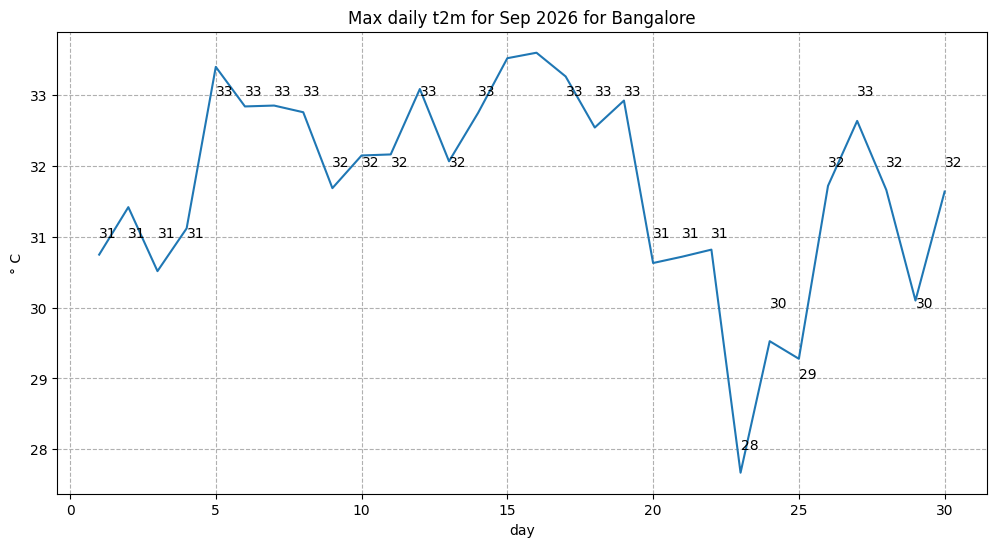

In [ ]:
## Code obtained from:
fig, ax = plt.subplots(1, 1, figsize = (12, 6))

ax.plot(bangalore_2026_max.day, bangalore_2026_max)
ax.set_title('Max daily t2m for Sep 2026 for Bangalore')
ax.set_ylabel('° C')
ax.set_xlabel('day')
ax.grid(linestyle='--')
for i,j in zip(bangalore_2026_max.day, np.around(bangalore_2026_max.values, 0).astype(int)):
    ax.annotate(str(j),xy=(i,j))
fig.savefig(f'{DATADIR}max_t2_bangalore.png')


In [ ]:
print('The maximum temperature in September 2026 in Bangalore was',
      np.around(bangalore_2026_max.max().values, 1), 'degrees Celsius.')

The maximum temperature in September 2026 in Bangalore was 33.6 degrees Celsius.


## Long-term temperature values

We go back to the bangalore_sep_t2m DataArray and select all the data before 2026:

In [ ]:
bangalore_sep_t2m_before_2026 = bangalore_sep_t2m.loc['1979':'2025']

In xarray, you can "slice" data. Also see above with using the "sel" method.

There is also something called .loc and .iloc. For more information regarding [**Indexing and Slicing**](https://docs.xarray.dev/en/stable/user-guide/indexing.html), please find the xarray documentation in this link.

Let's see how this looks:

In [ ]:
bangalore_sep_t2m_before_2026

<xarray.DataArray 't2m' (time: 33840)> Size: 271kB
array([21.63395324, 21.60073144, 22.00718042, ..., 21.27816262,
       21.35411447, 21.31359022])
Coordinates:
  * time     (time) datetime64[ns] 271kB 1979-09-01 ... 2025-09-30T23:00:00
Attributes:
    units:      K
    long_name:  2 metre temperature

Before computing the daily long term averages across all the years from the daily data, we compute the maximum values for each of the days in September for the entire period 1979-2025. We do so using a "resampling" method in xarray meaning we "reduce" according to a certain dimension (days here).

In [ ]:
bangalore_max = bangalore_sep_t2m_before_2026.resample(time='D').max().dropna('time')
bangalore_max

<xarray.DataArray 't2m' (time: 1410)> Size: 11kB
array([30.18964734, 28.31650099, 28.71575865, ..., 28.73395574,
       29.03229734, 29.29727667])
Coordinates:
  * time     (time) datetime64[ns] 11kB 1979-09-01 1979-09-02 ... 2025-09-30
Attributes:
    units:      K
    long_name:  2 metre temperature

We see that we have resampled and only have data for each day with the maximum temperature and this for the entire period 1978-2025. So this is for 30 days (1 month) times 47 as the number of years which equals 1410.

In [ ]:
bangalore_max.time

<xarray.DataArray 'time' (time: 1410)> Size: 11kB
array(['1979-09-01T00:00:00.000000000', '1979-09-02T00:00:00.000000000',
       '1979-09-03T00:00:00.000000000', ..., '2025-09-28T00:00:00.000000000',
       '2025-09-29T00:00:00.000000000', '2025-09-30T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 11kB 1979-09-01 1979-09-02 ... 2025-09-30
    expver   int32 4B 1
Attributes:
    long_name:  time

For each day, compute several statistics over the years now. Notice that here, we use another "reducer" called "groupby". We again find more information for this in the xarray tutorials here.

In [ ]:
bangalore_max_max = bangalore_max.groupby('time.day').max()
bangalore_max_min = bangalore_max.groupby('time.day').min()
bangalore_max_mid = bangalore_max.groupby('time.day').quantile(0.5)

The following data array prints out for each day the hottest temperature across all the years:

In [ ]:
bangalore_max_max

<xarray.DataArray 't2m' (day: 30)> Size: 240B
array([31.87798271, 31.44540533, 31.61683072, 32.10312403, 30.66235299,
       31.93195324, 31.66098587, 31.46385498, 30.87684179, 31.29796741,
       31.26742407, 32.01412179, 32.32123548, 32.22975249, 31.73300991,
       31.06740189, 31.39406306, 31.14024001, 31.74197721, 31.37657585,
       31.6625226 , 32.31822316, 31.55872584, 31.94890866, 31.5156004 ,
       31.40598723, 31.65637639, 31.98912191, 31.46954223, 31.46698578])
Coordinates:
  * day      (day) int64 240B 1 2 3 4 5 6 7 8 9 ... 22 23 24 25 26 27 28 29 30
Attributes:
    units:      K
    long_name:  2 metre temperature

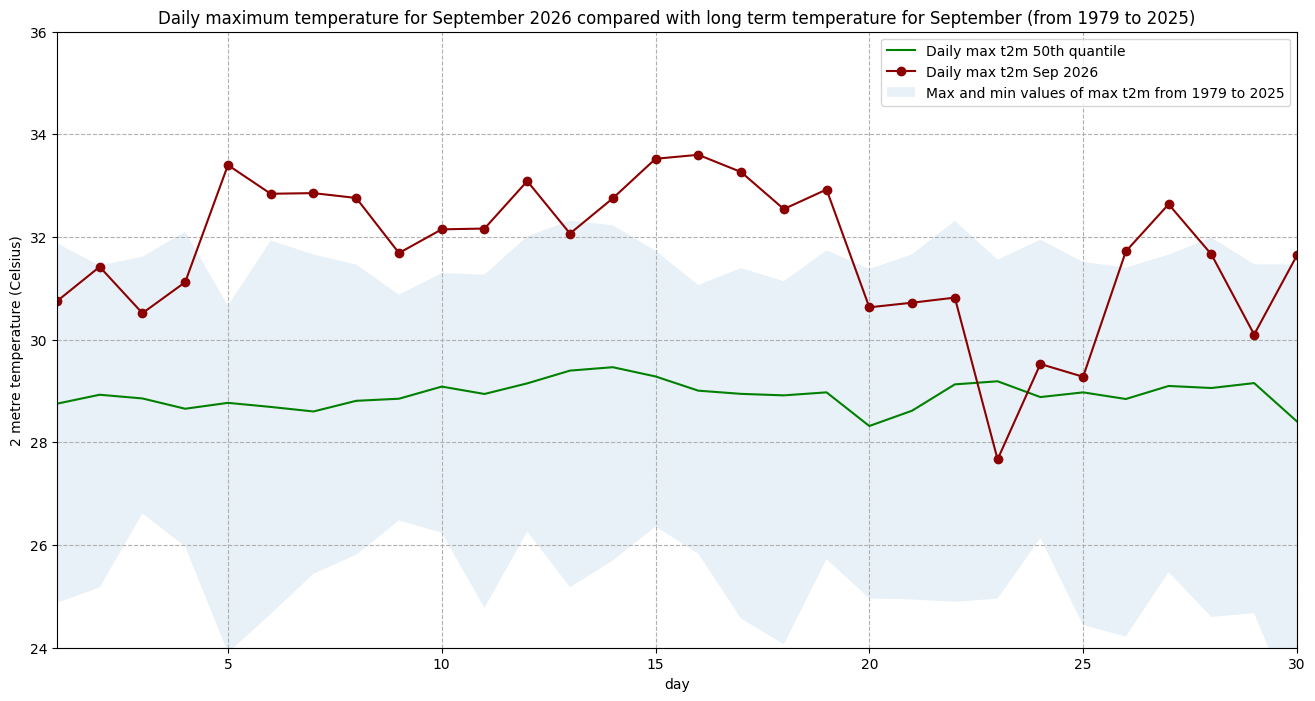

In [ ]:
## Code based on:
fig = plt.figure(figsize=(16,8))
ax = plt.subplot()

ax.plot(bangalore_2026_max.day.day, bangalore_max_mid, color='green', label='Daily max t2m 50th quantile')
ax.plot(bangalore_2026_max.day.day, bangalore_2026_max, 'o-', color='darkred', label='Daily max t2m Sep 2026')
ax.fill_between(bangalore_2026_max.day, bangalore_max_max, bangalore_max_min, alpha=0.1,
                label='Max and min values of max t2m from 1979 to 2025')

ax.set_xlim(1,30)
ax.set_ylim(24,36)
ax.set_title('Daily maximum temperature for September 2026 compared with long term temperature for September (from 1979 to 2025)')
ax.set_ylabel('2 metre temperature (Celsius)')
ax.set_xlabel('day')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels)
ax.grid(linestyle='--')

fig.savefig(f'{DATADIR}max_t2m_Sep_bangalore_comparison_2026.png')

## References

https://ecmwf-training.github.io/c3s-training/

https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-heatwave.html

https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-temp-record.html

<hr>